MODULO 3 CAPITOLO 6 VIDEO 4 " REGRESSIONE LASSO"

In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score


In [4]:
data = fetch_california_housing(as_frame = True)
X = data.data
y = data.target

display(X)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [5]:
display (y)


0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [6]:
#scaliamo i dati 

scaler = StandardScaler ()

X_scaled = scaler.fit_transform(X)
display (X_scaled)

array([[ 2.34476576,  0.98214266,  0.62855945, ..., -0.04959654,
         1.05254828, -1.32783522],
       [ 2.33223796, -0.60701891,  0.32704136, ..., -0.09251223,
         1.04318455, -1.32284391],
       [ 1.7826994 ,  1.85618152,  1.15562047, ..., -0.02584253,
         1.03850269, -1.33282653],
       ...,
       [-1.14259331, -0.92485123, -0.09031802, ..., -0.0717345 ,
         1.77823747, -0.8237132 ],
       [-1.05458292, -0.84539315, -0.04021111, ..., -0.09122515,
         1.77823747, -0.87362627],
       [-0.78012947, -1.00430931, -0.07044252, ..., -0.04368215,
         1.75014627, -0.83369581]], shape=(20640, 8))

In [7]:
#regressione lineare 
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y)
y_pred_lin = lin_reg.predict(X_scaled)

mse_lin = mean_squared_error(y, y_pred_lin)
r2_lin = r2_score(y, y_pred_lin)

print(f"MSE:\t{mse_lin:.4f}\nR2:\t{r2_lin}")

MSE:	0.5243
R2:	0.606232685199805


In [8]:
#valutazione della regressione lasso 

r2_lasso = []
mse_lasso = []
alphas = np.logspace(-4,1,100)

for a in alphas:
    lasso = Lasso(alpha = a)
    lasso.fit(X_scaled,y)
    y_pred = lasso.predict(X_scaled)
    mse_lasso.append(mean_squared_error(y,y_pred))
    r2_lasso.append(r2_score(y,y_pred))

results = pd.DataFrame({"alphas":alphas, "MSE": mse_lasso, "R2": r2_lasso})

display(results)



,alphas,MSE,R2
0,0.000100,0.524322,0.606232
1,0.000112,0.524322,0.606232
2,0.000126,0.524322,0.606232
3,0.000142,0.524322,0.606232
4,0.000159,0.524322,0.606232
...,...,...,...
95,6.280291,1.331550,0.000000
96,7.054802,1.331550,0.000000
97,7.924829,1.331550,0.000000
98,8.902151,1.331550,0.000000


In [9]:
#indice del valore del MSE, salviamo l'indice e a quale alpha corrisponde in modo manuale 

best_index_man = np.argmin(mse_lasso)
best_alpha_man = alphas[best_index_man]
best_mse_man = mse_lasso[best_index_man]
best_r2_man = r2_lasso[best_index_man]

print(f"Alpha Lasso:\t{best_alpha_man}\nMSE:\t{best_mse_man}\nR2:\t{best_r2_man}")



Alpha Lasso:	0.0001
MSE:	0.5243215460110524
R2:	0.6062322647677378


In [10]:
alphas_cv = alphas
lasso_cv = LassoCV(alphas = alphas_cv, cv = 5 , random_state=42, max_iter=1000)
lasso_cv.fit(X_scaled, y)

print(f"Alpha LassoCV:\t{lasso_cv.alpha_}")

y_pred_cv = lasso_cv.predict(X_scaled)
mse_cv = mean_squared_error(y, y_pred_cv)
r2_cv = r2_score(y,y_pred_cv)

print(f"MSE:\t{mse_cv}\nR2:\t{r2_cv}")



Alpha LassoCV:	0.002595024211399737
MSE:	0.52469805360532
R2:	0.6059495059457508


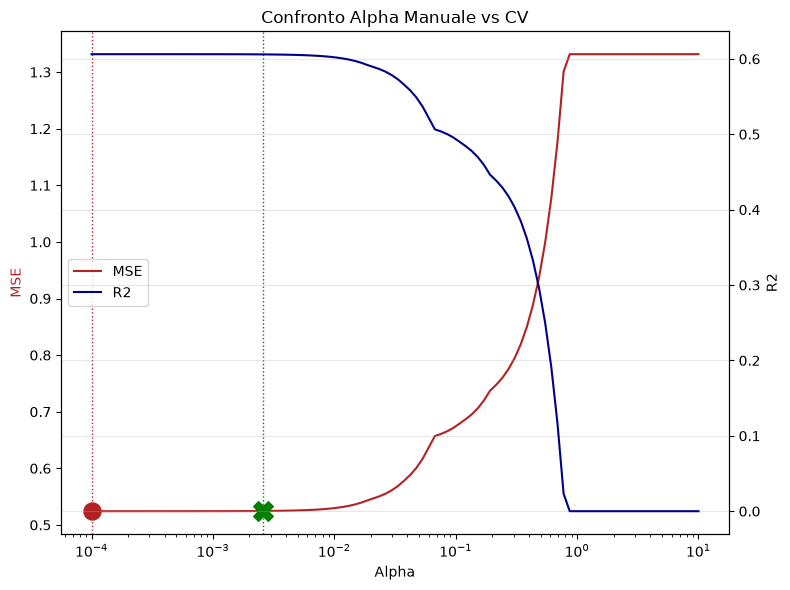

In [15]:
fig, ax1 = plt.subplots(figsize = (8,6))

l1 = ax1.plot(alphas, mse_lasso, "-", color = "firebrick", label = "MSE")
ax1.set_xscale("log")
ax1.set_xlabel("Alpha")
ax1.set_ylabel("MSE", color = "firebrick")

ax1.scatter(best_alpha_man, best_mse_man, color ="firebrick", s = 150 , zorder = 5, label = "Alpha Ottimale Manuale")
ax1.axvline(best_alpha_man, color = "firebrick", linestyle = ":", linewidth = 1)


ax1.scatter(lasso_cv.alpha_, mse_cv, color ="green", marker = "X", s = 200 , zorder = 5, label = "Alpha Ottimale CV")
ax1.axvline(lasso_cv.alpha_, color = "green", linestyle = ":", linewidth = 1)



ax2 = ax1.twinx()
l2 = ax2.plot(alphas, r2_lasso, "-", color = "darkblue", label = "R2")
ax2.set_ylabel("R2")

plt.title("Confronto Alpha Manuale vs CV")
plt.grid(alpha = 0.3)

lines = l1+l2
labels = [line.get_label() for line in lines]
ax1.legend(lines,labels, loc="center left")

plt.tight_layout()
plt.show()